# 06 · Innovation: proving each idea, and making the model safety-aware

**Goal:** Four extras for the innovation marks.
- **I1. Ablation study:** remove one idea at a time and measure the damage. This proves each idea helps, and shows *why* the forbidden temperatures are forbidden.
- **I2. Thermal-memory story:** how the error falls as we give the model longer and longer memory.
- **I3. Safety-aware alarm:** add a safety margin to the estimate and count caught overheating moments vs false alarms.
- **I4. Data-efficiency curve:** how much training data the model needs.

(**I5**, the demo app, is `app.py` in the repo root.)

**Inputs:** `data/processed/features.parquet`, `outputs/results/feature_list.json`, `modelling_summary.json`, `split_profiles.json`, and `test_predictions.csv` (for I3 only).

**Outputs:** `outputs/results/ablation.csv`, `memory_curve.csv`, `safety_alarm.csv`, `data_efficiency.csv`, `innovation_summary.json`; figures `innov_01` … `innov_04`.

**The test-set rule still holds:**
- I1, I2 and I4 use **cross-validation or validation inside the 63 training sessions**, so the test set is not re-used for these comparisons.
- I3 only post-processes the test predictions already saved in Phase 5. The model is not re-run on the test set.

## 1. Setup

In [1]:
import json
import random
import sys
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import GroupShuffleSplit

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src import config, features
from src.data import load_split
from src.modelling import group_cv, regression_metrics
from src.plotting import COLORS, save_figure, use_style

random.seed(config.SEED)
np.random.seed(config.SEED)
use_style()
warnings.filterwarnings("ignore", message="Usage of np.ndarray subset")
warnings.filterwarnings("ignore", category=ConvergenceWarning)
N_JOBS = 16

info = json.load(open(config.RESULTS_DIR / "feature_list.json"))
SETS = info["sets"]
modelling = json.load(open(config.RESULTS_DIR / "modelling_summary.json"))
evaluation = json.load(open(config.RESULTS_DIR / "evaluation_summary.json"))
FINAL = evaluation["final_model"]
split = load_split()

def final_model():
    # a fresh, unfitted copy of the final model with its Phase 4 settings
    if FINAL == "M5 LightGBM":
        return lgb.LGBMRegressor(subsample_freq=1, n_jobs=N_JOBS, random_state=config.SEED, verbose=-1, **modelling["best_lgbm_params"])
    if FINAL == "M4 Random Forest":
        return RandomForestRegressor(n_estimators=100, max_samples=0.5, n_jobs=N_JOBS, random_state=config.SEED, **modelling["best_rf_params"])
    if FINAL == "M3 Lasso":
        return Pipeline([("scale", StandardScaler()), ("model", Lasso(alpha=modelling["best_lasso_alpha"], max_iter=5000))])
    if FINAL == "M3 Ridge":
        return Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=modelling["best_ridge_alpha"]))])
    if FINAL == "M6 MLP (64-32)":
        return Pipeline([("scale", StandardScaler()),
                         ("model", MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-4, batch_size=512, learning_rate_init=1e-3,
                                                max_iter=40, early_stopping=False, random_state=config.SEED))])
    raise ValueError(FINAL)

print("Final model in Phase 5 (used for every experiment below):", FINAL)

Final model in Phase 5 (used for every experiment below): M6 MLP (64-32)


In [2]:
cols_needed = sorted(set(SETS["with_leakage"]) | {config.GROUP, config.TARGET})
feat = pd.read_parquet(config.PROJECT_DIR / "data" / "processed" / "features.parquet", columns=cols_needed)
train = feat[feat[config.GROUP].isin(split["train_profiles"])]
del feat
cv_data = train.iloc[::modelling["k_cv"]]
y = cv_data[config.TARGET].astype("float64")
groups = cv_data[config.GROUP]
print("CV rows:", len(cv_data), "| sessions:", groups.nunique())

_cv_cache = {}

def cv_rmse(cols):
    # the same input list always gives the same result (fixed seed), so identical runs are done only once
    key = tuple(sorted(cols))
    if key not in _cv_cache:
        fold_table, _ = group_cv(final_model(), cv_data[cols], y, groups)
        _cv_cache[key] = (float(fold_table["rmse"].mean()), float(fold_table["rmse"].std(ddof=0)), float(fold_table["mae"].mean()))
    return _cv_cache[key]

CV rows: 118980 | sessions: 63


## 2. I1: ablation study
We keep the **same model (the final model from Phase 5, with its Phase 4 settings), the same rows and the same 5 session-folds**, and only change the inputs:

| Variant | Inputs |
|---|---|
| full | all 45 (8 raw + 5 physics + 32 EWMA) |
| no EWMA | 13 (raw + physics, no memory) |
| no engineered | 24 (raw + EWMAs of the raw signals only; no physics features) |
| no torque | 39 (everything except torque, mechanical power and torque EWMAs) |
| raw only | 8 raw signals |
| **with leakage** | 48 (full + `pm`, `stator_tooth`, `stator_yoke`): **forbidden**, run only to show the cheat |

In [3]:
variants = {"full": SETS["full"], "no EWMA": SETS["no_ewma"], "no engineered": SETS["no_engineered"],
            "no torque": SETS["no_torque"], "raw only": SETS["raw"], "with leakage (forbidden)": SETS["with_leakage"]}
abl_rows = []
for name, cols in variants.items():
    rmse, std, mae = cv_rmse(cols)
    abl_rows.append({"variant": name, "n_features": len(cols), "cv_rmse": rmse, "cv_rmse_std": std, "cv_mae": mae})
    print(f"{name:26s} {len(cols):2d} features  CV RMSE {rmse:.3f} ± {std:.3f} °C  MAE {mae:.3f}")
ablation = pd.DataFrame(abl_rows)
full_rmse = float(ablation.loc[ablation["variant"] == "full", "cv_rmse"].iloc[0])
ablation["change_vs_full"] = ablation["cv_rmse"] - full_rmse
ablation.to_csv(config.RESULTS_DIR / "ablation.csv", index=False)
ablation.round(3)

full                       45 features  CV RMSE 4.919 ± 0.763 °C  MAE 3.116


no EWMA                    13 features  CV RMSE 13.176 ± 1.367 °C  MAE 9.312


no engineered              24 features  CV RMSE 6.561 ± 0.617 °C  MAE 4.524


no torque                  39 features  CV RMSE 4.809 ± 1.033 °C  MAE 2.886


raw only                    8 features  CV RMSE 13.407 ± 1.379 °C  MAE 9.689


with leakage (forbidden)   48 features  CV RMSE 1.146 ± 0.112 °C  MAE 0.848


,variant,n_features,cv_rmse,cv_rmse_std,cv_mae,change_vs_full
0,full,45,4.919,0.763,3.116,0.000
1,no EWMA,13,13.176,1.367,9.312,8.257
2,no engineered,24,6.561,0.617,4.524,1.642
3,no torque,39,4.809,1.033,2.886,-0.110
4,raw only,8,13.407,1.379,9.689,8.488
5,with leakage (forbidden),48,1.146,0.112,0.848,-3.774


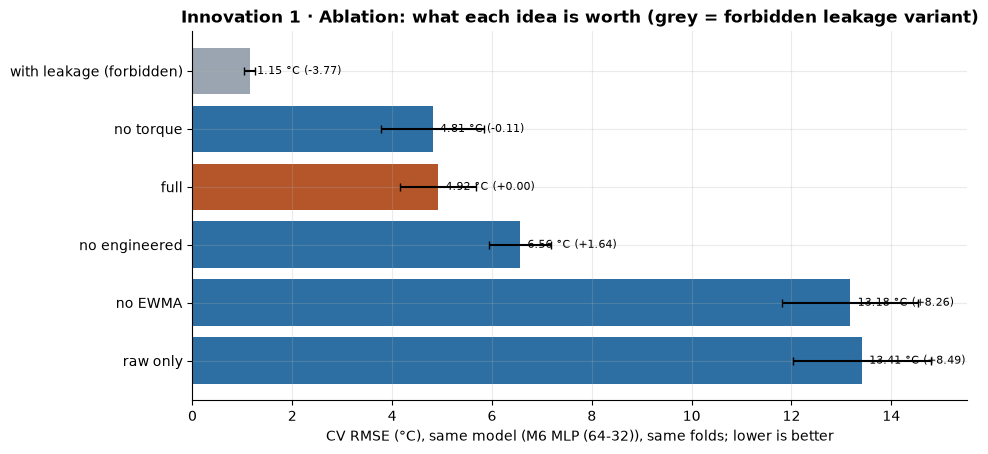

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.8))
plot = ablation.sort_values("cv_rmse", ascending=True)
colors = ["#9aa5b1" if "leakage" in v else (COLORS["stator_winding"] if v == "full" else COLORS["coolant"]) for v in plot["variant"]]
ax.barh(plot["variant"], plot["cv_rmse"], xerr=plot["cv_rmse_std"], color=colors, capsize=3)
for i, (v, c) in enumerate(zip(plot["cv_rmse"], plot["change_vs_full"])):
    ax.text(v + 0.15, i, f"{v:.2f} °C ({c:+.2f})", va="center", fontsize=8)
ax.invert_yaxis()
ax.set_xlabel(f"CV RMSE (°C), same model ({FINAL}), same folds; lower is better")
ax.set_title("Innovation 1 · Ablation: what each idea is worth (grey = forbidden leakage variant)")
save_figure(fig, "innov_01_ablation.png")
plt.show()

## 3. I2: the thermal-memory story
Starting from **raw + physics features (no memory)**, we add the EWMA features span by span: 1 min, then 5, then 15, then 45 min. If thermal memory is real, the error should fall as the memory gets longer.

no memory                    13 features  CV RMSE 13.176 ± 1.367 °C


1 min                        21 features  CV RMSE 9.171 ± 0.951 °C


1 min + 5 min                29 features  CV RMSE 5.158 ± 0.666 °C


1 min + 5 min + 15 min       37 features  CV RMSE 4.996 ± 1.180 °C
1 min + 5 min + 15 min + 45 min 45 features  CV RMSE 4.919 ± 0.763 °C


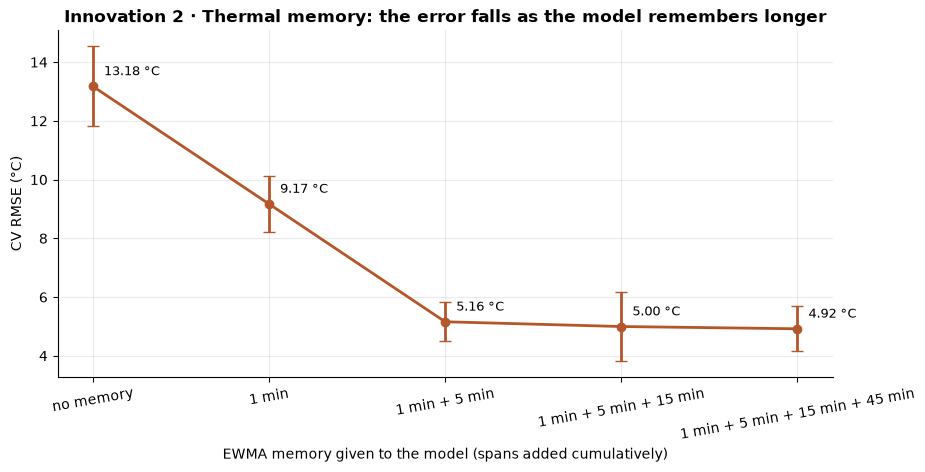

In [5]:
base = SETS["no_ewma"]
steps = [("no memory", [])]
spans_so_far = []
for span in features.EWMA_SPANS:
    spans_so_far.append(span)
    steps.append((" + ".join(f"{s // 120} min" for s in spans_so_far), list(spans_so_far)))
mem_rows = []
for label, spans in steps:
    cols = base + [features.ewma_name(c, s) for c in features.EWMA_BASES for s in spans]
    rmse, std, mae = cv_rmse(cols)
    mem_rows.append({"memory": label, "longest_span_min": (max(spans) // 120 if spans else 0), "n_features": len(cols),
                     "cv_rmse": rmse, "cv_rmse_std": std, "cv_mae": mae})
    print(f"{label:28s} {len(cols):2d} features  CV RMSE {rmse:.3f} ± {std:.3f} °C")
memory_curve = pd.DataFrame(mem_rows)
memory_curve.to_csv(config.RESULTS_DIR / "memory_curve.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.errorbar(range(len(memory_curve)), memory_curve["cv_rmse"], yerr=memory_curve["cv_rmse_std"], marker="o", capsize=4,
            color=COLORS["stator_winding"], lw=2)
for i, v in enumerate(memory_curve["cv_rmse"]):
    ax.annotate(f"{v:.2f} °C", (i, v), textcoords="offset points", xytext=(8, 8), fontsize=9)
ax.set_xticks(range(len(memory_curve)))
ax.set_xticklabels(memory_curve["memory"], rotation=10)
ax.set_xlabel("EWMA memory given to the model (spans added cumulatively)")
ax.set_ylabel("CV RMSE (°C)")
ax.set_title("Innovation 2 · Thermal memory: the error falls as the model remembers longer")
save_figure(fig, "innov_02_memory_curve.png")
plt.show()

## 4. I3: safety-aware alarm
A real motor-protection system cares most about **not missing overheating**. So we add a **safety margin** to the estimate:

$$\text{alarm if } \hat{T} + k\cdot\sigma \ge T_{\text{hot}}$$

- σ = the standard deviation of the final model's **out-of-fold errors on the training sessions** (Phase 4). It's a measure of typical error that never looked at the test set.
- T_hot = **104.79 °C**, the 90th percentile of the *training* winding temperatures, the same "hot" definition as Phase 5.
- k = 0 (no margin), 1 and 2.

For each k we count, over all test rows (the saved Phase 5 predictions):
- **caught:** the share of truly hot rows that raised the alarm (recall);
- **false alarms:** the share of not-hot rows that raised it;
- **precision:** of all alarms, the share that were real.

In [6]:
preds = pd.read_csv(config.RESULTS_DIR / "test_predictions.csv")
# The CSV rounds temperatures to 3 decimals. Test session 21 plateaus at ~104.79 °C, exactly at the
# hot threshold, so rounding would push ~270 plateau rows over the line. We therefore take the
# full-precision measured temperatures (same rows, same order) from the features file.
labels = pd.read_parquet(config.PROJECT_DIR / "data" / "processed" / "features.parquet", columns=[config.GROUP, config.TARGET])
labels = labels[labels[config.GROUP].isin(split["test_profiles"])]
assert len(labels) == len(preds) and np.allclose(np.round(labels[config.TARGET].to_numpy(dtype="float64"), 3), preds["actual"])
preds["actual"] = labels[config.TARGET].to_numpy(dtype="float64")
final_col = "pred_" + evaluation["final_model"].split(" ")[0].lower()
sigma = float(modelling["oof_best"]["residual_std"])
eda = json.load(open(config.RESULTS_DIR / "eda_summary.json"))
T_HOT = float(eda["target_train_stats"]["90%"])
actual_hot = preds["actual"] >= T_HOT
alarm_rows = []
for k in [0, 1, 2]:
    alarm = (preds[final_col] + k * sigma) >= T_HOT
    tp = int((alarm & actual_hot).sum()); fn = int((~alarm & actual_hot).sum())
    fp = int((alarm & ~actual_hot).sum()); tn = int((~alarm & ~actual_hot).sum())
    alarm_rows.append({"k": k, "margin_c": round(k * sigma, 3), "hot_rows": int(actual_hot.sum()),
                       "caught_pct": 100 * tp / (tp + fn) if tp + fn else float("nan"),
                       "missed_hot_minutes": fn / 120,
                       "false_alarm_pct": 100 * fp / (fp + tn) if fp + tn else float("nan"),
                       "false_alarm_minutes": fp / 120,
                       "precision_pct": 100 * tp / (tp + fp) if tp + fp else float("nan")})
safety = pd.DataFrame(alarm_rows)
safety.to_csv(config.RESULTS_DIR / "safety_alarm.csv", index=False)
print(f"sigma (out-of-fold residual std) = {sigma:.3f} °C, T_hot = {T_HOT:.3f} °C, hot test rows = {int(actual_hot.sum())} (Phase 5: {evaluation['under_prediction'][evaluation['final_model']]['hot_rows']})")
assert int(actual_hot.sum()) == evaluation["under_prediction"][evaluation["final_model"]]["hot_rows"]
safety.round(2)

sigma (out-of-fold residual std) = 4.959 °C, T_hot = 104.791 °C, hot test rows = 14496 (Phase 5: 14496)


,k,margin_c,hot_rows,caught_pct,missed_hot_minutes,false_alarm_pct,false_alarm_minutes,precision_pct
0,0,0.00,14496,57.20,51.70,0.70,7.38,90.36
1,1,4.96,14496,66.43,40.55,2.30,24.28,76.78
2,2,9.92,14496,70.04,36.19,5.84,61.62,57.86


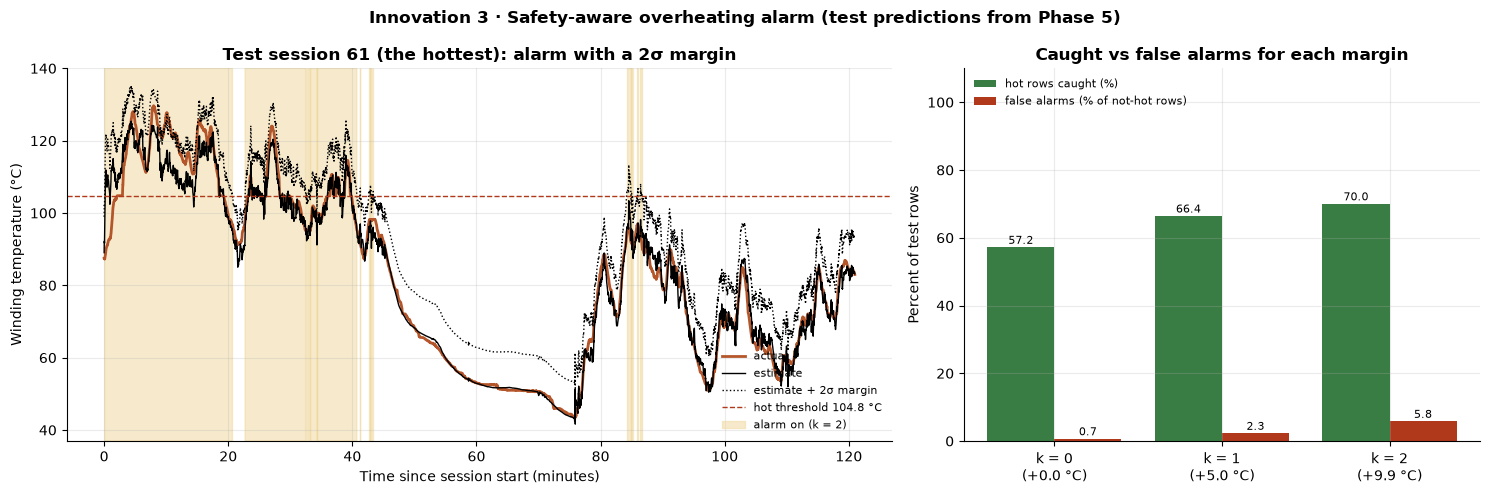

In [7]:
hot_session = int(preds.loc[preds["actual"].idxmax(), config.GROUP])
s = preds[preds[config.GROUP] == hot_session]
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.plot(s["minute"], s["actual"], color=COLORS["stator_winding"], lw=2, label="actual")
ax.plot(s["minute"], s[final_col], color="black", lw=1, label="estimate")
ax.plot(s["minute"], s[final_col] + 2 * sigma, color="black", lw=1, ls=":", label="estimate + 2σ margin")
ax.axhline(T_HOT, color="#b0391b", ls="--", lw=1, label=f"hot threshold {T_HOT:.1f} °C")
alarm2 = (s[final_col] + 2 * sigma) >= T_HOT
ax.fill_between(s["minute"], 0, 1, where=alarm2.to_numpy(), transform=ax.get_xaxis_transform(), color="#f0d79a", alpha=0.5, label="alarm on (k = 2)")
ax.set_xlabel("Time since session start (minutes)")
ax.set_ylabel("Winding temperature (°C)")
ax.set_title(f"Test session {hot_session} (the hottest): alarm with a 2σ margin")
ax.legend(loc="lower right", fontsize=8)
ax = axes[1]
x = np.arange(len(safety))
ax.bar(x - 0.2, safety["caught_pct"], width=0.4, color=COLORS["current"], label="hot rows caught (%)")
ax.bar(x + 0.2, safety["false_alarm_pct"], width=0.4, color="#b0391b", label="false alarms (% of not-hot rows)")
for i, (c, f) in enumerate(zip(safety["caught_pct"], safety["false_alarm_pct"])):
    ax.text(i - 0.2, c + 1, f"{c:.1f}", ha="center", fontsize=8)
    ax.text(i + 0.2, f + 1, f"{f:.1f}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([f"k = {k}\n(+{m:.1f} °C)" for k, m in zip(safety["k"], safety["margin_c"])])
ax.set_ylabel("Percent of test rows")
ax.set_ylim(0, 110)
ax.set_title("Caught vs false alarms for each margin")
ax.legend(loc="upper left", fontsize=8)
fig.suptitle("Innovation 3 · Safety-aware overheating alarm (test predictions from Phase 5)", fontweight="bold")
fig.tight_layout()
save_figure(fig, "innov_03_safety_alarm.png")
plt.show()

## 5. Where the biggest test errors come from: the first minutes of a session
Phase 5 showed huge errors right at some session starts (up to 60 °C in session 21). From the **saved** Phase 5 predictions (no new test evaluation) we compare the error in the first 5 minutes of each test session with the rest.

**Why it happens:** at a session's first row, pandas' `ewm(adjust=True)` sets every EWMA equal to the current raw value. So if a session *starts* under heavy load, the 15 and 45-minute "memories" look as if the motor had been at that load for a long time, and the model predicts a hot winding while it is actually still cold. The opposite happens for sessions that start already hot. A real controller would run its EWMAs continuously from power-on, so this is mostly an artefact of cutting the recordings into sessions.

In [8]:
pred_cols = [c for c in preds.columns if c.startswith("pred_")]
early = preds["minute"] < 5
start_rows = []
for col in pred_cols:
    e = preds[col] - preds["actual"]
    start_rows.append({"prediction": col, "mae_first_5_min": float(e[early].abs().mean()), "signed_first_5_min": float(e[early].mean()),
                       "mae_after_5_min": float(e[~early].abs().mean()), "max_abs_first_5_min": float(e[early].abs().max())})
session_start = pd.DataFrame(start_rows)
session_start.to_csv(config.RESULTS_DIR / "session_start_errors.csv", index=False)
print(f"Share of test rows in the first 5 min of a session: {100 * early.mean():.2f} %")
session_start.round(3)

Share of test rows in the first 5 min of a session: 2.55 %


,prediction,mae_first_5_min,signed_first_5_min,mae_after_5_min,max_abs_first_5_min
0,pred_m6,12.345,12.044,3.466,60.312
1,pred_m5,12.519,11.822,2.607,74.873
2,pred_m3,18.640,18.625,2.583,73.573
3,pred_b1,16.862,10.733,20.233,34.385


## 6. I4: data-efficiency curve
How much training data does the model need? We set aside **20 % of the training sessions as a validation set** (`GroupShuffleSplit`, seed 42; the test sessions are not involved). Then we train on 25 %, 50 %, 75 % and 100 % of the *remaining* sessions. For the smaller fractions we repeat 3 times with different random session picks and average.

Development sessions:

 50 | validation sessions: 13


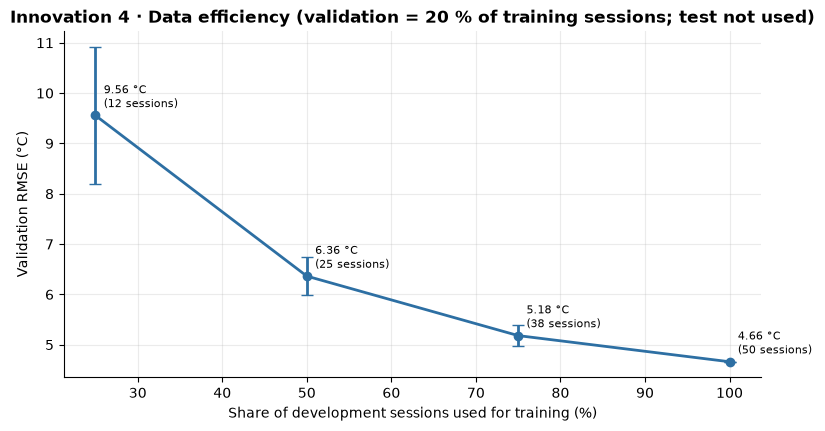

,fraction,n_sessions,val_rmse,val_rmse_std
0,0.25,12,9.556,1.365
1,0.50,25,6.363,0.372
2,0.75,38,5.181,0.210
3,1.00,50,4.662,NaN


In [9]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=config.SEED)
dev_idx, val_idx = next(gss.split(cv_data, groups=groups))
dev, val = cv_data.iloc[dev_idx], cv_data.iloc[val_idx]
dev_sessions = np.array(sorted(dev[config.GROUP].unique()))
print("Development sessions:", len(dev_sessions), "| validation sessions:", val[config.GROUP].nunique())
FULL = SETS["full"]
rng = np.random.default_rng(config.SEED)
eff_rows = []
for frac in [0.25, 0.5, 0.75, 1.0]:
    repeats = 1 if frac == 1.0 else 3
    for r in range(repeats):
        n = max(2, int(round(frac * len(dev_sessions))))
        chosen = dev_sessions if frac == 1.0 else rng.choice(dev_sessions, size=n, replace=False)
        part = dev[dev[config.GROUP].isin(chosen)]
        model = final_model().fit(part[FULL], part[config.TARGET])
        m = regression_metrics(val[config.TARGET], model.predict(val[FULL]))
        eff_rows.append({"fraction": frac, "repeat": r, "n_sessions": int(n), "train_rows": int(len(part)),
                         "val_rmse": m["rmse"], "val_mae": m["mae"]})
eff = pd.DataFrame(eff_rows)
eff.to_csv(config.RESULTS_DIR / "data_efficiency.csv", index=False)
eff_mean = eff.groupby("fraction").agg(n_sessions=("n_sessions", "first"), val_rmse=("val_rmse", "mean"), val_rmse_std=("val_rmse", "std")).reset_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(eff_mean["fraction"] * 100, eff_mean["val_rmse"], yerr=eff_mean["val_rmse_std"].fillna(0), marker="o", capsize=4, color=COLORS["coolant"], lw=2)
for _, r in eff_mean.iterrows():
    ax.annotate(f"{r['val_rmse']:.2f} °C\n({int(r['n_sessions'])} sessions)", (r["fraction"] * 100, r["val_rmse"]), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xlabel("Share of development sessions used for training (%)")
ax.set_ylabel("Validation RMSE (°C)")
ax.set_title("Innovation 4 · Data efficiency (validation = 20 % of training sessions; test not used)")
save_figure(fig, "innov_04_data_efficiency.png")
plt.show()
eff_mean.round(3)

## 7. Save the summary

In [10]:
summary = {
    "model_used": FINAL,
    "ablation": ablation.round(4).to_dict(orient="records"),
    "memory_curve": memory_curve.round(4).to_dict(orient="records"),
    "safety": {"sigma_oof_c": round(sigma, 4), "t_hot_c": T_HOT, "session_plotted": hot_session,
               "table": safety.round(3).to_dict(orient="records")},
    "session_start": {"share_rows_first_5_min": float(early.mean()), "table": session_start.round(4).to_dict(orient="records")},
    "data_efficiency": {"validation_sessions": int(val[config.GROUP].nunique()), "development_sessions": int(len(dev_sessions)),
                        "table": eff_mean.round(4).to_dict(orient="records")},
}
with open(config.RESULTS_DIR / "innovation_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print("Saved innovation_summary.json")

Saved innovation_summary.json


## 8. What we found (numbers from the outputs above and `innovation_summary.json`; added after the run, with no re-execution)
- **I1 ablation** (final MLP, same rows and folds; CV RMSE):
  - full 4.919 °C;
  - **no EWMA 13.176 (+8.26)**;
  - no physics features 6.561 (+1.64);
  - no torque 4.809 (−0.11, within noise);
  - raw only 13.407;
  - **with forbidden temperatures 1.146**, which is the proof they would be a cheat.
- **I2 memory curve:** 13.176 (no memory) → 9.171 (1 min) → 5.158 (+5 min) → 4.996 (+15 min) → 4.919 °C (+45 min). Five minutes of memory gives most of the gain, matching the 2.5-min lag from EDA.
- **I3 safety alarm** (σ = 4.959 °C out-of-fold, threshold 104.791 °C, 14,496 hot test rows, the same count as Phase 5):

  | k | Margin | Hot rows caught | False alarms | Precision | Missed hot minutes |
  |---|---|---|---|---|---|
  | 0 | 0 °C | 57.2 % | 0.70 % | 90.4 % | 51.7 |
  | 1 | 4.96 °C | 66.4 % | 2.30 % | 76.8 % | 40.6 |
  | 2 | 9.92 °C | **70.0 %** | 5.84 % | 57.9 % | 36.2 |

  A margin trades false alarms for caught overheating. Even k = 2 still misses 30 % of hot rows, because the MLP under-reads by about 6 °C when hot. That's a limitation we state openly.
- **Session starts:** the first 5 minutes of each test session (2.55 % of test rows) have MAE **12.34 °C** for the MLP vs 3.47 °C afterwards (signed +12.04 °C, i.e. over-prediction). LightGBM: 12.52 vs 2.61; Ridge: 18.64 vs 2.58. The EWMA warm-up artefact explains a large share of the remaining error.
- **I4 data efficiency** (13 validation sessions): 9.56 °C (12 sessions) → 6.36 (25) → 5.18 (38) → 4.66 °C (50). Still falling, so more recorded sessions would help.
- **[BUG fixed during this phase]** `test_predictions.csv` rounds temperatures to 3 decimals. Test session 21 plateaus at about 104.79 °C, exactly at the threshold, and rounding counted 269 extra rows as "hot" (14,765 instead of 14,496). Section 4 now reads the full-precision temperatures and asserts the Phase 5 count.
